# **[실습] 영화 유사도**
* https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset?resource=download
* IMDB :  https://www.imdb.com/

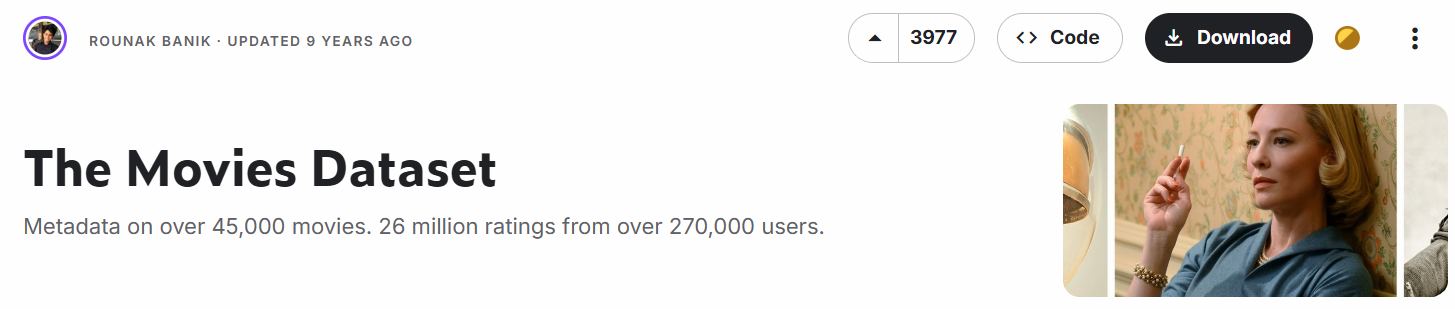

In [1]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import warnings 
warnings.filterwarnings('ignore')

# **Data Load**

In [18]:
df = pd.read_csv("../datas/movies_metadata.csv")[['title','overview']]
df['title'] = df['title'].str.lower()
df.head(2)

,title,overview
0,toy story,"Led by Woody, Andy's toys live happily in his ..."
1,jumanji,When siblings Judy and Peter discover an encha...


In [19]:
df = df[:20000].copy()

In [20]:
df.shape

(20000, 2)

In [21]:
df.loc[0, 'overview']

"Led by Woody, Andy's toys live happily in his room until Andy's birthday brings Buzz Lightyear onto the scene. Afraid of losing his place in Andy's heart, Woody plots against Buzz. But when circumstances separate Buzz and Woody from their owner, the duo eventually learns to put aside their differences."

# 결측 삭제

In [22]:
df = df.dropna()
df.shape

(19863, 2)

# 중복제거

In [23]:
df = df.drop_duplicates()
df.shape

(19852, 2)

In [24]:
df.info()

<class 'pandas.DataFrame'>
Index: 19852 entries, 0 to 19999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   title     19852 non-null  str  
 1   overview  19852 non-null  str  
dtypes: str(2)
memory usage: 6.8 MB


# 유사도 계산
* TF-IDF
* cosine_similarity

In [25]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['overview'])
print(f"TFIDF 행렬 크기 : {tfidf_matrix.shape}")
print(f"사전크기(단어갯수) : {tfidf_matrix.shape[1]}")

#print(tfidf.vocabulary_)

TFIDF 행렬 크기 : (19852, 47487)
사전크기(단어갯수) : 47487


In [26]:
cosine_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)
cosine_matrix.shape

(19852, 19852)

In [27]:
cos_df = pd.DataFrame(cosine_matrix, index=[df['title'].str.lower()] , columns=[df['title'].str.lower()])
cos_df.head(2)

title,toy story,jumanji,grumpier old men,waiting to exhale,father of the bride part ii,heat,sabrina,tom and huck,sudden death,goldeneye,...,never say... never!,calmos,how to make love to a woman,"after fall, winter",violeta went to heaven,rebellion,versailles,two in the wave,lotte reiniger: homage to the inventor of the silhouette film,"rko production 601: the making of 'kong, the eighth wonder of the world'"
title,,,,,,,,,,,,,,,,,,,,,
toy story,1.000000,0.015749,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,0.000000,0.009962,0.060986,0.00000,0.0,0.0,0.024596,0.0,0.0,0.0
jumanji,0.015749,1.000000,0.049063,0.0,0.0,0.051862,0.0,0.0,0.106416,0.0,...,0.029259,0.000000,0.000000,0.00426,0.0,0.0,0.000000,0.0,0.0,0.0


In [28]:
cos_df.loc['toy story'].shape

(1, 19852)

In [29]:
cos_df.loc['toy story'].squeeze().sort_values(ascending=False)[1:5]

title                 
toy story 3               0.525896
toy story 2               0.462658
the 40 year old virgin    0.279526
the champ                 0.200631
Name: (toy story,), dtype: float64

In [32]:
df.loc[df['title']=='toy story','overview'].values

<ArrowStringArray>
['Led by Woody, Andy's toys live happily in his room until Andy's birthday brings Buzz Lightyear onto the scene. Afraid of losing his place in Andy's heart, Woody plots against Buzz. But when circumstances separate Buzz and Woody from their owner, the duo eventually learns to put aside their differences.']
Length: 1, dtype: str

In [34]:
df.loc[df['title']=='toy story 3','overview'].values

<ArrowStringArray>
['Woody, Buzz, and the rest of Andy's toys haven't been played with in years. With Andy about to go to college, the gang find themselves accidentally left at a nefarious day care center. The toys must band together to escape and return home to Andy.']
Length: 1, dtype: str

In [35]:
df.loc[df['title']=='the 40 year old virgin','overview'].values

<ArrowStringArray>
['Andy Stitzer has a pleasant life with a nice apartment and a job stamping invoices at an electronics store. But at age 40, there's one thing Andy hasn't done, and it's really bothering his sex-obsessed male co-workers: Andy is still a virgin. Determined to help Andy get laid, the guys make it their mission to de-virginize him. But it all seems hopeless until Andy meets small business owner Trish, a single mom.']
Length: 1, dtype: str